# 価格と性能が、製品の選ばれやすさにどう関係するか

## 概要

『マーケティングサイエンスの理論と実践』第4章「選ばれる要因を推定する」は、価格・性能・ブランドと選択の関係を扱う。この記事では、実務の課題、ロジット選択モデルの理論、Pythonによる推定、施策の比較の順に本章を紹介する。スマートフォンの模擬データを使い、1万円の値下げと駆動時間の3時間延長を比べる。

### 実行環境

仮想環境は **wa-src(3.14.6)**、Pythonは **3.14.6** である。NumPy、SciPy、Polars、statsmodels、Matplotlibを使用する。上から順に実行すると、図は `04_nb_files` にSVG形式で保存される。小数の表示は有効数字3桁とし、計算途中では丸めない。

In [1]:
from importlib.metadata import version
from pathlib import Path
from pprint import pprint
import platform

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import matplotlib_fontja  # 日本語の軸ラベルを表示する。
from matplotlib.ticker import FuncFormatter, ScalarFormatter
from scipy.special import expit, softmax
from scipy.stats import gumbel_r, norm
from statsmodels.discrete.conditional_models import ConditionalLogit
from IPython.display import Latex, SVG, display

# ノートブックのフォルダーとリポジトリ直下のどちらからも実行できる。
base_dir = Path.cwd()
if (base_dir / "blog/04/04_nb.ipynb").exists():
    base_dir = base_dir / "blog/04"
figure_dir = base_dir / "04_nb_files"
figure_dir.mkdir(exist_ok=True)


def sig3(value):
    """末尾のゼロを残し、有効数字3桁にそろえる。"""
    return format(float(value), "#.3g").removesuffix(".")


def show_math(tex):
    """重要式の原稿の区切りを、出力用の $$ に変換する。"""
    tex = tex.strip()
    if tex.startswith(r"\(") and tex.endswith(r"\)"):
        tex = tex[2:-2].strip()
    display(Latex("$$\n" + tex + "\n$$"))


def save_svg(fig, filename):
    """SVGを保存し、同じ画像を出力欄にも埋め込む。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if isinstance(axis.get_major_formatter(), ScalarFormatter):
                axis.set_major_formatter(FuncFormatter(
                    lambda value, _: str(int(value))
                    if float(value).is_integer() else sig3(value)
                ))
    path = figure_dir / filename
    fig.savefig(path, format="svg", bbox_inches="tight")
    plt.close(fig)
    display(SVG(filename=str(path)))


np.set_printoptions(formatter={"float_kind": sig3})
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "svg.fonttype": "path"})
colors = ["#326B9C", "#B56836", "#45806B"]

print("実行環境: wa-src(3.14.6)")
print(f"Python: {platform.python_version()}")
for package in ["numpy", "scipy", "polars", "statsmodels", "matplotlib",
                "matplotlib-fontja", "ipython"]:
    print(f"{package}: {version(package)}")

実行環境: wa-src(3.14.6)
Python: 3.14.6
numpy: 2.4.6
scipy: 1.18.1
polars: 2.1.0
statsmodels: 0.14.6
matplotlib: 3.11.2
matplotlib-fontja: 1.1.0
ipython: 9.18.1


## 1. 選ばれる理由を数値で比べる

本章の導入では、市場シェアが下がったオンラインサービスで、「価格が高い」「使いにくい」「認知が低い」という意見が並ぶ場面を取り上げる。改善の優先順位を決めるには、それぞれの条件と選択との関係を調べる必要がある。

購入後のアンケートで説明された理由と、実際の選択が一致するとは限らない。そこで、条件の異なる候補から一つを選ぶ実験を行い、属性の重みを推定する。私なら、係数の大小だけを示すより、具体的な変更後の選択確率まで示したい。その方が施策を比較しやすいと考える。

## 2. 効用から選択確率を求める

### 2.1 観測できる部分と誤差に分ける

消費者$i$が製品$j$から得る価値を効用$U_{ij}$とする。観測した属性から計算する部分$V_{ij}$と、観測できない要因$\varepsilon_{ij}$に分ける。以下では選択課題の添字を省く。

In [2]:
show_math(r"""\(
U_{ij}=V_{ij}+\varepsilon_{ij},\qquad
V_{ij}=\alpha_j+\sum_{k=1}^{K}\beta_k x_{ijk}
\)""")

<IPython.core.display.Latex object>

$\alpha_j$は製品固有の定数、$\beta_k$は属性1単位当たりの重みである。効用が最大の製品を選ぶと仮定するが、誤差は観測できないため、選択を確率で表す。基本形では全回答者に共通の係数を使う。

### 2.2 ガンベル分布から多項ロジットへ

誤差が互いに独立な標準ガンベル分布に従うと仮定する。累積分布関数$F$と、その微分である密度$f$は次式となる。

In [3]:
show_math(r"""\(
F(s)=e^{-e^{-s}},\qquad
f(s)=\frac{dF(s)}{ds}=e^{-s}e^{-e^{-s}}
\)""")

<IPython.core.display.Latex object>

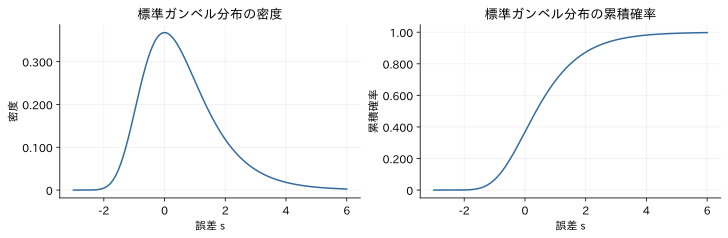

In [4]:
s = np.linspace(-3, 6, 400)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
for ax, values, title, label in zip(
    axes, [gumbel_r.pdf(s), gumbel_r.cdf(s)],
    ["標準ガンベル分布の密度", "標準ガンベル分布の累積確率"],
    ["密度", "累積確率"],
):
    ax.plot(s, values, color=colors[0])
    ax.set(xlabel="誤差 s", ylabel=label, title=title)
    ax.grid(alpha=0.200)
save_svg(fig, "01_gumbel.svg")

$\varepsilon_{ij}=s$を固定すると、他の各製品$k$について$\varepsilon_{ik}<s+V_{ij}-V_{ik}$となる確率を掛け合わせられる。最後に$s$を積分する。

In [5]:
show_math(r"""\(
\begin{aligned}
P_{ij}
&=P(U_{ij}>U_{ik},\ \forall k\ne j)\\
&=\int_{-\infty}^{\infty}f(s)
  \prod_{k\ne j}F(s+V_{ij}-V_{ik})\,ds\\
&=\int_{-\infty}^{\infty}e^{-s}
  \exp\!\left[-e^{-s}\left(1+\sum_{k\ne j}e^{V_{ik}-V_{ij}}\right)\right]ds.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

$C=1+\sum_{k\ne j}e^{V_{ik}-V_{ij}}$と置く。$u=e^{-s}$なら$ds=-du/u$であり、積分範囲は$s:-\infty\to\infty$から$u:\infty\to0$へ変わる。

In [6]:
show_math(r"""\(
\begin{aligned}
P_{ij}
&=\int_{\infty}^{0}u e^{-Cu}\left(-\frac{du}{u}\right)
=\int_{0}^{\infty}e^{-Cu}\,du\\
&=\left[-\frac{e^{-Cu}}{C}\right]_{0}^{\infty}
=\frac{1}{C}\\
&=\frac{1}{\sum_{k=1}^{J}e^{V_{ik}-V_{ij}}}
=\frac{e^{V_{ij}}}{\sum_{k=1}^{J}e^{V_{ik}}}.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

これが多項ロジット（MNL）の確率式である。分母が共通なので合計は1となる。ただし、2製品の確率の比には他の候補が入らない。これをIIAと呼ぶ。

In [7]:
show_math(r"""\(
\frac{P_{iA}}{P_{iB}}
=\frac{e^{V_{iA}}/\sum_k e^{V_{ik}}}{e^{V_{iB}}/\sum_k e^{V_{ik}}}
=e^{V_{iA}-V_{iB}}
\)""")

<IPython.core.display.Latex object>

図は自家用車と赤バスの効用が等しい場合である。同じ効用の青バスを加えると、MNLでは各確率が3分の1になる。赤バスと青バスが特によく似ていることは、この基本形では表せない。

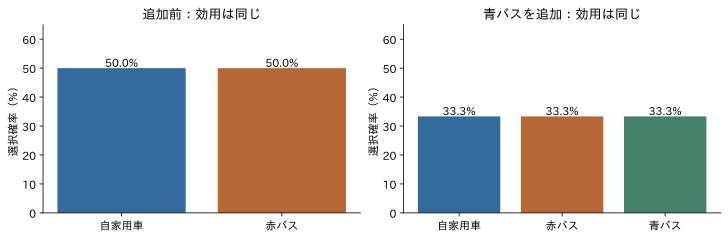

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
for ax, labels, title in zip(
    axes, [["自家用車", "赤バス"], ["自家用車", "赤バス", "青バス"]],
    ["追加前：効用は同じ", "青バスを追加：効用は同じ"],
):
    probabilities = softmax(np.zeros(len(labels)))
    bars = ax.bar(labels, 100 * probabilities, color=colors[:len(labels)])
    ax.bar_label(bars, labels=[f"{sig3(100 * p)}%" for p in probabilities])
    ax.set(ylabel="選択確率（%）", ylim=(0, 65), title=title)
save_svg(fig, "02_iia.svg")

### 2.3 係数の単位と支払意思額

価格を万円、駆動時間を時間で測る。ブランドAを基準に、B・Cなら1となるダミー変数を入れる。ブランドと製品が一対一なので、その係数には製品固有の違いも含まれる。

In [9]:
show_math(r"""\(
V_{ij}=\beta_p p_{ij}+\beta_h h_{ij}
+\beta_B d_{ijB}+\beta_C d_{ijC}
\)""")

<IPython.core.display.Latex object>

単位の異なる係数の絶対値を、そのまま重要度として比べることはできない。駆動時間の向上と価格上昇が相殺される条件から、支払意思額（WTP）を求める。

In [10]:
show_math(r"""\(
\begin{aligned}
\Delta V&=\beta_p\Delta p+\beta_h\Delta h=0\\
\beta_p\Delta p&=-\beta_h\Delta h\\
\mathrm{WTP}_h=\frac{\Delta p}{\Delta h}
&=-\frac{\beta_h}{\beta_p}.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

単位は万円／時間であり、実際の支払額ではなく、モデル上の効用が釣り合う価格差である。

### 2.4 二項ロジットとプロビット

二択では効用差$z=V_1-V_0$だけで確率が決まる。分子と分母を$e^{V_1}$で割ると、シグモイド関数になる。

In [11]:
show_math(r"""\(
\begin{aligned}
p&=\frac{e^{V_1}}{e^{V_1}+e^{V_0}}
=\frac{1}{1+e^{V_0-V_1}}
=\frac{1}{1+e^{-z}}\\
1-p&=\frac{e^{-z}}{1+e^{-z}},\qquad
\frac{p}{1-p}=e^z,\qquad \log\frac{p}{1-p}=z.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

効用が等しければ$p=0.500$となる。一方、プロビットは正規分布の誤差を使う。二つの誤差が独立で分散$\sigma^2$なら、その差の分散は$2\sigma^2$となる。

In [12]:
show_math(r"""\(
P_1=\Phi\!\left(\frac{V_1-V_0}{\sqrt{2}\sigma}\right),\qquad
\Phi(z)=\int_{-\infty}^{z}\frac{e^{-s^2/2}}{\sqrt{2\pi}}\,ds
\)""")

<IPython.core.display.Latex object>

右図では、ロジスティック分布の標準偏差$\pi/\sqrt{3}$を使って両分布の分散を1にそろえる。曲線は近いが一致はしない。多項プロビットは誤差間の相関を扱える一方、一般に確率の計算に数値積分を要する。

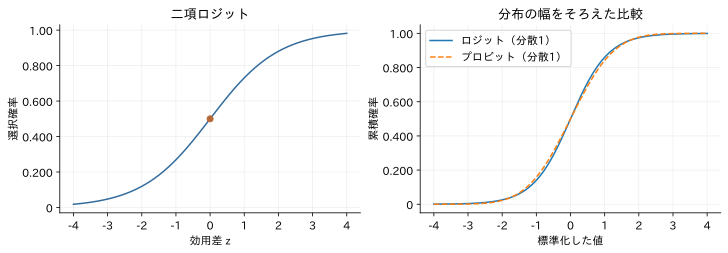

In [13]:
z = np.linspace(-4, 4, 400)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
axes[0].plot(z, expit(z), color=colors[0])
axes[0].scatter([0], [0.500], color=colors[1], zorder=3)
axes[0].set(xlabel="効用差 z", ylabel="選択確率", title="二項ロジット")
# 分散1に標準化したロジスティック分布のCDFと標準正規CDFを比較する。
axes[1].plot(z, expit(np.pi * z / np.sqrt(3)), label="ロジット（分散1）")
axes[1].plot(z, norm.cdf(z), "--", label="プロビット（分散1）")
axes[1].set(xlabel="標準化した値", ylabel="累積確率", title="分布の幅をそろえた比較")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.200)
save_svg(fig, "03_logit_probit.svg")

## 3. Pythonで推定し、結果を読む

### 3.1 選択データを作る

本章と同じ500人・各8課題・3製品の模擬データを作る。1行が一つの課題の一製品を表し、選ばれた製品だけ`chosen=1`となる。乱数シードと生成手順は元のノートブックに合わせる。価格係数は1円当たり$-0.0000280$、駆動時間は$0.120$とする。

500人 × 8課題 × 3製品 = 12,000行
shape: (6, 6)
┌───────────────┬───────────────┬───────┬────────┬───────────┬───────────────┐
│ respondent_id ┆ choice_set_id ┆ brand ┆ chosen ┆ price_yen ┆ battery_hours │
│ ---           ┆ ---           ┆ ---   ┆ ---    ┆ ---       ┆ ---           │
│ i64           ┆ i64           ┆ str   ┆ i64    ┆ i64       ┆ i64           │
╞═══════════════╪═══════════════╪═══════╪════════╪═══════════╪═══════════════╡
│ 0             ┆ 0             ┆ A     ┆ 1      ┆ 69800     ┆ 15            │
│ 0             ┆ 0             ┆ B     ┆ 0      ┆ 69800     ┆ 12            │
│ 0             ┆ 0             ┆ C     ┆ 0      ┆ 79800     ┆ 12            │
│ 0             ┆ 1             ┆ A     ┆ 0      ┆ 89800     ┆ 15            │
│ 0             ┆ 1             ┆ B     ┆ 1      ┆ 69800     ┆ 9             │
│ 0             ┆ 1             ┆ C     ┆ 0      ┆ 89800     ┆ 15            │
└───────────────┴───────────────┴───────┴────────┴───────────┴───────────────┘


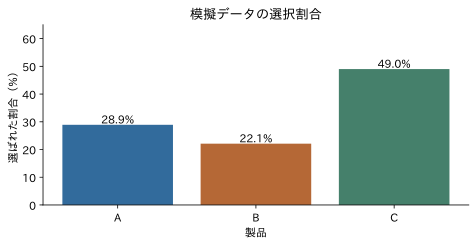

In [14]:
rng = np.random.default_rng(42)
n_respondents, n_tasks = 500, 8
products = ["A", "B", "C"]
price_levels = {"A": [69800, 79800, 89800], "B": [59800, 69800, 79800],
                "C": [79800, 89800, 99800]}
hours_levels = {"A": [9, 12, 15], "B": [9, 12], "C": [12, 15, 18]}
brand_premium = {"A": 0, "B": -0.300, "C": 0.500}

records = []
for respondent in range(n_respondents):
    for task in range(n_tasks):
        attributes, utilities = {}, {}
        for product in products:
            price = int(rng.choice(price_levels[product]))
            hours = int(rng.choice(hours_levels[product]))
            v = -0.0000280 * price + 0.120 * hours + brand_premium[product]
            utilities[product] = v + rng.gumbel()
            attributes[product] = (price, hours)
        chosen = max(utilities, key=utilities.get)
        for product in products:
            price, hours = attributes[product]
            records.append((respondent, task, product, int(product == chosen),
                            price, hours))

df = pl.DataFrame(records, orient="row", schema=[
    "respondent_id", "choice_set_id", "brand", "chosen", "price_yen", "battery_hours"
])
# 各課題に3製品、選択1件があることと、欠損・重複がないことを確認する。
check = df.group_by("respondent_id", "choice_set_id").agg(
    pl.len().alias("rows"), pl.col("brand").n_unique().alias("brands"),
    pl.col("chosen").sum().alias("selected"),
)
assert df.null_count().to_numpy().sum() == 0
assert check.filter((pl.col("rows") != 3) | (pl.col("brands") != 3)
                    | (pl.col("selected") != 1)).is_empty()
print(f"{n_respondents}人 × {n_tasks}課題 × 3製品 = {df.height:,}行")
print(df.head(6))

observed_share = np.array([
    df.filter(pl.col("brand") == product)["chosen"].mean() for product in products
])
fig, ax = plt.subplots(figsize=(6.5, 3.3), layout="constrained")
bars = ax.bar(products, observed_share * 100, color=colors)
ax.bar_label(bars, labels=[f"{sig3(p * 100)}%" for p in observed_share])
ax.set(xlabel="製品", ylabel="選ばれた割合（%）", ylim=(0, 65), title="模擬データの選択割合")
save_svg(fig, "04_observed_choices.svg")

この割合には価格や性能の違いも含まれるため、ブランドだけの効果とは読めない。

### 3.2 最尤法で係数を推定する

課題番号は回答者ごとに重複するため、回答者IDと組み合わせて一意にする。価格は万円へ変換する。全製品に共通する切片を加えても確率は変わらないので、共通切片は入れない。

選択結果を$y_{ijt}$とすると、選ばれた候補の確率を掛けた尤度$L$を最大化する。積を対数で和に変えると、最適化に用いる式が得られる。

In [15]:
show_math(r"""\(
\begin{aligned}
L&=\prod_{i,t,j}P_{ijt}^{y_{ijt}},\qquad
\ell=\log L=\sum_{i,t,j}y_{ijt}\log P_{ijt}\\
\log P_{ijt}&=V_{ijt}-\log\sum_k e^{V_{ikt}}\\
\widehat{\mathbf{b}}&=\underset{\mathbf{b}}{\operatorname{argmax}}\;
\sum_{i,t,j}y_{ijt}\left(V_{ijt}-\log\sum_k e^{V_{ikt}}\right),\qquad
V_{ijt}=\mathbf{x}_{ijt}^{\mathsf T}\mathbf{b}.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

$\mathbf{x}_{ijt}$は4属性のベクトル、$\mathbf{b}$は係数ベクトルである。`ConditionalLogit`に課題IDを渡すと、各課題から一つを選ぶMNLとして推定できる。

In [16]:
df_model = df.with_columns(
    (pl.col("respondent_id") * n_tasks + pl.col("choice_set_id")).alias("task_id"),
    (pl.col("price_yen") / 10000).alias("price_man"),
    (pl.col("brand") == "B").cast(pl.Int8).alias("brand_B"),
    (pl.col("brand") == "C").cast(pl.Int8).alias("brand_C"),
).sort("task_id", "brand")
features = ["price_man", "battery_hours", "brand_B", "brand_C"]
X = df_model.select(features).to_numpy()
y = df_model["chosen"].to_numpy()
groups = df_model["task_id"].to_numpy()

model = ConditionalLogit(y, X, groups=groups)
result = model.fit(disp=False, maxiter=200)
beta = np.asarray(result.params)
ci = np.asarray(result.conf_int())
true_beta = np.array([-0.280, 0.120, -0.300, 0.500])
print("属性、設定した係数、推定係数、95%信頼区間")
pprint([(name, sig3(truth), sig3(value), tuple(sig3(v) for v in interval))
        for name, truth, value, interval in zip(features, true_beta, beta, ci)],
       width=100)

属性、設定した係数、推定係数、95%信頼区間
[('price_man', '-0.280', '-0.312', ('-0.362', '-0.262')),
 ('battery_hours', '0.120', '0.138', ('0.120', '0.157')),
 ('brand_B', '-0.300', '-0.374', ('-0.481', '-0.268')),
 ('brand_C', '0.500', '0.459', ('0.356', '0.563'))]


### 3.3 オッズ比と不確かさを確認する

価格の推定係数は$-0.312$、駆動時間は$0.138$となる。ある製品の属性だけを1単位増やすと、比較先の製品に対する相対オッズは次の倍率で変わる。

In [17]:
show_math(r"""\(
\mathrm{OR}_k
=\frac{P'_j/P'_m}{P_j/P_m}
=\frac{e^{V_j+\beta_k-V_m}}{e^{V_j-V_m}}
=e^{\beta_k}
\)""")

<IPython.core.display.Latex object>

属性、オッズ比、95%信頼区間、p値
[('price_man', '0.732', ('0.696', '0.770'), '3.87e-34'),
 ('battery_hours', '1.15', ('1.13', '1.17'), '2.72e-49'),
 ('brand_B', '0.688', ('0.618', '0.765'), '6.11e-12'),
 ('brand_C', '1.58', ('1.43', '1.76'), '2.95e-18')]


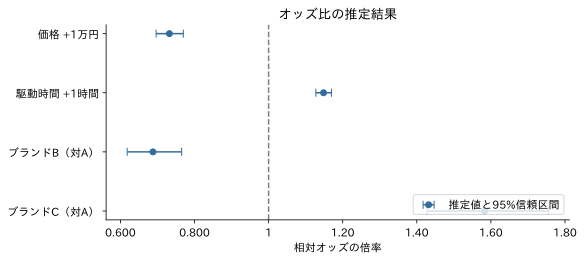

In [18]:
odds = np.exp(beta)
odds_ci = np.exp(ci)
labels = ["価格 +1万円", "駆動時間 +1時間", "ブランドB（対A）", "ブランドC（対A）"]
print("属性、オッズ比、95%信頼区間、p値")
pprint([(name, sig3(value), tuple(sig3(v) for v in interval), sig3(p))
        for name, value, interval, p in zip(features, odds, odds_ci, result.pvalues)],
       width=100)
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.errorbar(odds, np.arange(4),
            xerr=np.vstack([odds - odds_ci[:, 0], odds_ci[:, 1] - odds]),
            fmt="o", capsize=4, color=colors[0], label="推定値と95%信頼区間")
ax.axvline(1, linestyle="--", color="gray")
ax.set(yticks=np.arange(4), yticklabels=labels, xlabel="相対オッズの倍率",
       title="オッズ比の推定結果")
ax.invert_yaxis()
ax.legend(loc="lower right")
save_svg(fig, "05_odds_ratios.svg")

駆動時間のオッズ比は$1.15$である。確率そのものが15%増えるという意味ではない。信頼区間は模擬データの各課題を独立とする仮定に基づく。実データの繰り返し回答では、回答者単位のブートストラップなどで不確かさを調べる。

### 3.4 WTPを計算する

駆動時間のWTPは約$0.444$万円／時間となる。区間も示すため、係数の共分散行列$\mathbf{S}$を使うデルタ法を適用する。係数比を各係数で微分し、変化の大きさをベクトル$\mathbf{g}$にまとめる。

In [19]:
show_math(r"""\(
\begin{aligned}
w_k&=-\frac{\beta_k}{\beta_p},\qquad
\frac{\partial w_k}{\partial\beta_p}=\frac{\beta_k}{\beta_p^2},\qquad
\frac{\partial w_k}{\partial\beta_k}=-\frac{1}{\beta_p}\\
\mathrm{SE}(\hat w_k)&\approx\sqrt{\mathbf{g}^{\mathsf T}\mathbf{S}\mathbf{g}},\qquad
\mathrm{CI}_{95\%}\approx\hat w_k\pm1.96\,\mathrm{SE}(\hat w_k).
\end{aligned}
\)""")

<IPython.core.display.Latex object>

属性、WTP、95%信頼区間（万円：駆動時間は1時間当たり）
[('battery_hours', '0.444', ('0.354', '0.534')),
 ('brand_B', '-1.20', ('-1.50', '-0.898')),
 ('brand_C', '1.47', ('1.18', '1.77'))]


<IPython.core.display.Latex object>

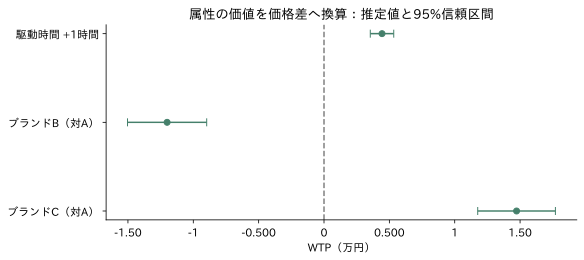

In [20]:
# 価格係数の区間が0を含む場合、単純な係数比の解釈は控える。
assert ci[0, 1] < 0, "価格係数を確認してからWTPを解釈する"
covariance = np.asarray(result.cov_params())
wtp, wtp_lower, wtp_upper = [], [], []
for k in [1, 2, 3]:
    value = -beta[k] / beta[0]
    gradient = np.zeros(4)
    gradient[0] = beta[k] / beta[0] ** 2
    gradient[k] = -1 / beta[0]
    se = np.sqrt(gradient @ covariance @ gradient)
    wtp.append(value)
    wtp_lower.append(value - 1.96 * se)
    wtp_upper.append(value + 1.96 * se)

wtp, wtp_lower, wtp_upper = map(np.asarray, [wtp, wtp_lower, wtp_upper])
print("属性、WTP、95%信頼区間（万円：駆動時間は1時間当たり）")
pprint([(name, sig3(value), (sig3(lo), sig3(hi)))
        for name, value, lo, hi in zip(features[1:], wtp, wtp_lower, wtp_upper)])
show_math(r"\(\widehat{\mathrm{WTP}}_h=-\frac{\hat\beta_h}{\hat\beta_p}\approx "
          + sig3(wtp[0]) + r"\;\text{万円/時間}\)")

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.errorbar(wtp, np.arange(3), xerr=np.vstack([wtp - wtp_lower, wtp_upper - wtp]),
            fmt="o", capsize=4, color=colors[2])
ax.axvline(0, color="gray", linestyle="--")
ax.set(yticks=np.arange(3), yticklabels=labels[1:], xlabel="WTP（万円）",
       title="属性の価値を価格差へ換算：推定値と95%信頼区間")
ax.invert_yaxis()
save_svg(fig, "06_wtp.svg")

価格係数が0に近いと、この比は不安定になる。また、ブランドのWTPも、この例では製品固有の違いを含む。

### 3.5 値下げと駆動時間の延長を比べる

Bを69,800円・12時間、Cを89,800円・15時間に固定する。Aの79,800円・12時間を基準に、価格だけ、または駆動時間だけを変更して確率を計算し直す。

条件、Aの選択確率（%）、変更前との差（ポイント）
[('変更前', '27.1', '0.00'),
 ('1万円の値下げ', '33.6', '6.57'),
 ('3時間の延長', '36.0', '8.91')]


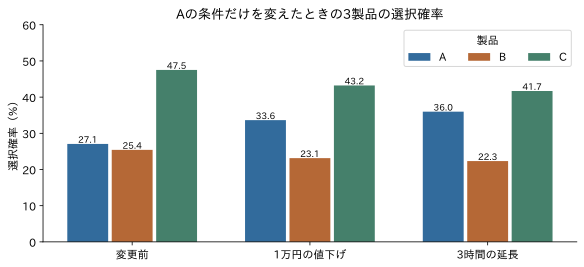

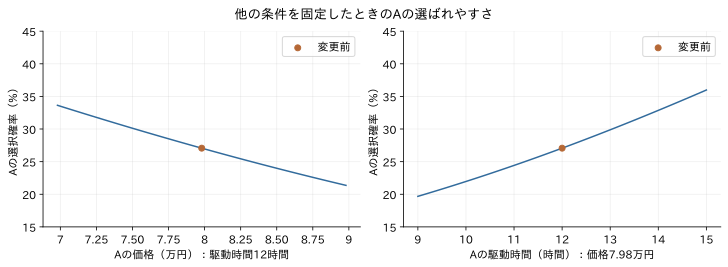

In [21]:
def choice_prob(profiles):
    # softmaxは最大効用を引いて計算し、指数関数の桁あふれを防ぐ。
    return softmax(np.asarray(profiles) @ beta)


base = np.array([[7.98, 12, 0, 0], [6.98, 12, 1, 0], [8.98, 15, 0, 1]])
price_down, battery_up = base.copy(), base.copy()
price_down[0, 0] = 6.98
battery_up[0, 1] = 15
scenario_names = ["変更前", "1万円の値下げ", "3時間の延長"]
probabilities = np.vstack([choice_prob(p) for p in [base, price_down, battery_up]])
assert np.allclose(probabilities.sum(axis=1), 1)
print("条件、Aの選択確率（%）、変更前との差（ポイント）")
pprint([(name, sig3(100 * p[0]), sig3(100 * (p[0] - probabilities[0, 0])))
        for name, p in zip(scenario_names, probabilities)])

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
positions = np.arange(3)
for j, product in enumerate(products):
    bars = ax.bar(positions + (j - 1) * 0.250, probabilities[:, j] * 100,
                  width=0.230, label=product, color=colors[j])
    ax.bar_label(bars, labels=[sig3(100 * p) for p in probabilities[:, j]], fontsize=9)
ax.set(xticks=positions, xticklabels=scenario_names, ylabel="選択確率（%）",
       ylim=(0, 60), title="Aの条件だけを変えたときの3製品の選択確率")
ax.legend(title="製品", ncol=3)
save_svg(fig, "07_scenarios.svg")

# 候補範囲内で、価格と駆動時間をそれぞれ連続的に変える。
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for ax, column, values, xlabel in zip(
    axes, [0, 1], [np.linspace(6.98, 8.98, 100), np.linspace(9, 15, 100)],
    ["Aの価格（万円）：駆動時間12時間", "Aの駆動時間（時間）：価格7.98万円"],
):
    curve = []
    for value in values:
        profiles = base.copy()
        profiles[0, column] = value
        curve.append(choice_prob(profiles)[0])
    ax.plot(values, 100 * np.asarray(curve), color=colors[0])
    ax.scatter([base[0, column]], [100 * probabilities[0, 0]],
               color=colors[1], label="変更前", zorder=3)
    ax.set(xlabel=xlabel, ylabel="Aの選択確率（%）", ylim=(15, 45))
    ax.legend()
    ax.grid(alpha=0.200)
fig.suptitle("他の条件を固定したときのAの選ばれやすさ")
save_svg(fig, "08_sensitivity.svg")

Aの選択確率は変更前の27.1%から、値下げで33.6%、駆動時間の延長で36.0%となる。この条件では3時間延長の方が大きく増える。ただし、A・B・Cから必ず一つ選ぶ条件での試算であり、市場全体の購入確率や販売数ではない。開発費、値下げによる粗利の減少、実施期間も比べる必要がある。

## 結論

この記事では、ロジット選択モデルで属性の重みを推定し、WTPと選択確率で施策を比較する手順を紹介した。

モデルから得られるのは、仮定と提示した候補に基づく比較である。私は、ここで候補を絞り、小規模な販売テストで購入数と利益を確認する使い方が実務に合うと考える。

[『マーケティングサイエンスの理論と実践』](https://gihyo.jp/book/2026/978-4-297-16025-8)第4章では、選択実験の設計、係数の読み方、モデルの限界まで説明している。詳しい実装は[本書のサポートページ](https://github.com/gihyo-book/marketing_science_book)に掲載されている。